# LiDAR BEV : inspection et objectif centre

Inspection CPU du point cloud, des features PFN/contexte et des annotations KITTI. La head facultative predit uniquement les centres Car et leur offset XY. Les poids sont aleatoires : ces vues ne montrent pas un detecteur entraine. Aucun telechargement, entrainement ou calcul GPU n'est lance automatiquement.

In [1]:
from pathlib import Path
import sys
import json
import subprocess
import torch
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next((path for path in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
             if (path / 'src/rgb_lidar_fusion').is_dir() and (path / 'pyproject.toml').is_file()), None)
if ROOT is None:
    raise RuntimeError('Open this notebook from the repository or notebooks directory.')
sys.path.insert(0, str(ROOT / 'src'))
from rgb_lidar_fusion.camera_bev import BEVGridConfig
from rgb_lidar_fusion.lidar_center_model import LidarCenterDiagnostic
from rgb_lidar_fusion.lidar_bev_analysis import analyze_lidar_bev_sample, plot_lidar_bev_sample
from rgb_lidar_fusion.kitti_label_data import audit_kitti_labels
print(f'ROOT={ROOT}')


ROOT=/home/mathieu.drouin/codes/ai-projects/rgb-lidar-fusion-tensorrt/rgb-lidar-fusion-tensorrt


## Parametres
Changer SAMPLE_IDS pour inspecter quelques frames. Le modele est initialise une seule fois sur CPU, avec la meme seed pour toutes les frames. Le diagnostic GPU reste dans un processus distinct.

In [5]:
DATA_ROOT = ROOT / 'data/kitti/training'
SAMPLE_IDS = ['000366']
GRID = BEVGridConfig((0.0, 50.0), (-25.0, 25.0), (-3.0, 3.0), 0.20)
SEED = 13
SCORE_THRESHOLD = 0.3
RUN_ANNOTATION_AUDIT = True
RUN_GPU_PROBE = False
MINIMUM_FREE_GPU_MEMORY_MIB = 2048
AUDIT_PATH = ROOT / 'results/analysis/lidar_bev/annotation_audit.json'
torch.set_num_threads(2)
with torch.random.fork_rng(devices=[]):
    torch.random.default_generator.manual_seed(SEED)
    model = LidarCenterDiagnostic().cpu().eval()
print(f'data={DATA_ROOT.resolve()} exists={DATA_ROOT.is_dir()} grid={GRID.shape}')
print('Weights: random, untrained. No camera checkpoint is required.')


data=/home/mathieu.drouin/codes/ai-projects/rgb-lidar-fusion-tensorrt/rgb-lidar-fusion-tensorrt/data/kitti/training exists=True grid=(250, 250)
Weights: random, untrained. No camera checkpoint is required.


## Annotations
Le rapport local verifie les correspondances de fichiers, le format et la construction des cibles, pas la perfection des annotations humaines. Si les labels manquent, lancer explicitement depuis un terminal : `pdm run python scripts/prepare_kitti_labels.py --download`. Les autres modalites ne seront pas retelechargees.

In [3]:
if RUN_ANNOTATION_AUDIT:
    audit = audit_kitti_labels(DATA_ROOT, grid=GRID)
elif AUDIT_PATH.is_file():
    audit = json.loads(AUDIT_PATH.read_text())
else:
    audit = None
if audit is not None:
    if audit.get('data_root') != str(DATA_ROOT.resolve()):
        print('Cached audit refers to another/unknown root; rerun RUN_ANNOTATION_AUDIT for this dataset.')
    display(audit)
else:
    print('No audit report found; set RUN_ANNOTATION_AUDIT=True to check current local files.')


{'ready': True,
 'data_root': '/home/mathieu.drouin/codes/ai-projects/rgb-lidar-fusion-tensorrt/rgb-lidar-fusion-tensorrt/data/kitti/training',
 'frame_count': 512,
 'class_counts': {'Pedestrian': 290,
  'Truck': 71,
  'Car': 1947,
  'Cyclist': 125,
  'DontCare': 1010,
  'Misc': 76,
  'Van': 179,
  'Tram': 40,
  'Person_sitting': 19},
 'target_car_count': 1715,
 'frames_with_supervision': 512,
 'errors': [],
 'warnings': [],
 'scope': 'Structural/calibration checks, not proof of perfect human annotations or sequence-disjoint splits.'}

## Frames et cibles
Les rectangles verts sont les annotations Car, les autres labels sont gris. Les zones inconnues/DontCare ne sont pas des negatifs par defaut. Le domaine negatif exige que toute la colonne verticale de la cellule se projette dans l'image ; une annotation Car explicite conserve sa cellule positive. Les RMS ne sont pas des scores objets. Les scores de la head sont non entraines.

000366: observed_cells=10315 retained=52915 dropped=5591
Car targets=2 supervised_cells=32004 ignored_labels=8
Untrained objective components: {'total': 175.33177185058594, 'heatmap': 175.14151000976562, 'offset': 0.19026565551757812}


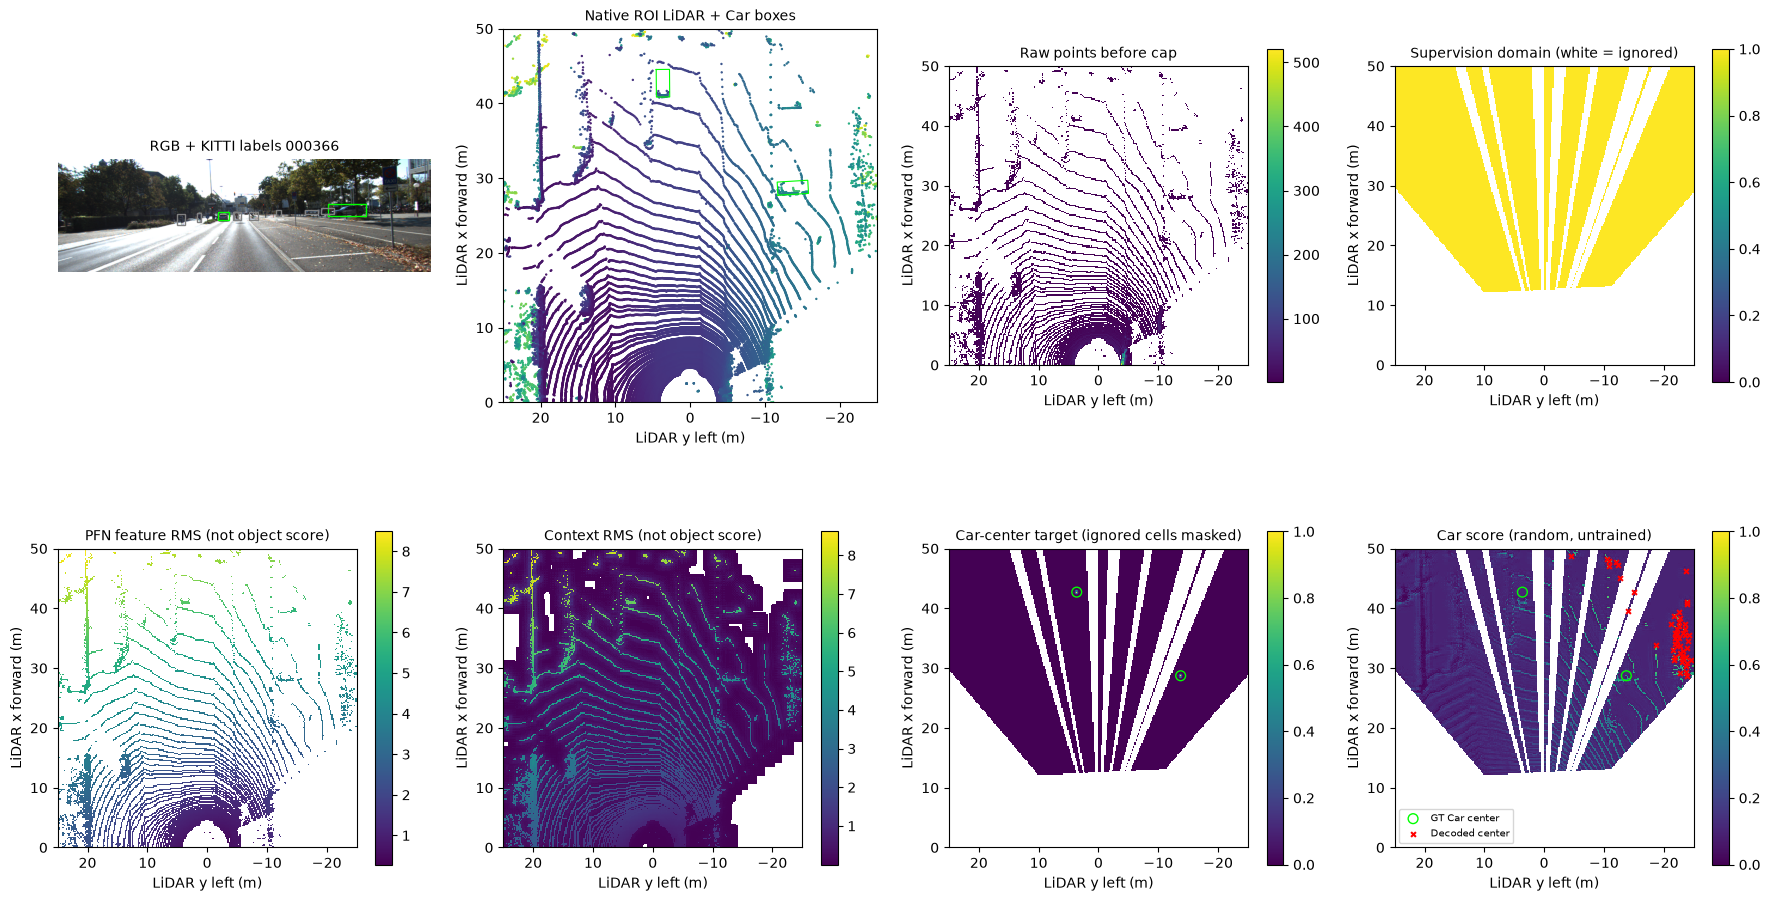

In [6]:
if not DATA_ROOT.is_dir():
    print(f'KITTI data missing: {DATA_ROOT}. See data/README.md.')
else:
    for sample_id in SAMPLE_IDS:
        sample = analyze_lidar_bev_sample(DATA_ROOT, sample_id, grid=GRID, model=model,
                                          score_threshold=SCORE_THRESHOLD)
        print(f'{sample_id}: observed_cells={int((sample.point_count > 0).sum())} '
              f'retained={sample.retained_points} dropped={sample.dropped_points}')
        if sample.targets is not None:
            print(f'Car targets={len(sample.targets.centers_vehicle)} '
                  f'supervised_cells={int(sample.targets.supervision_mask.sum())} '
                  f'ignored_labels={sample.targets.ignored_label_count}')
            print(f'Untrained objective components: {sample.loss}')
        figure = plot_lidar_bev_sample(sample)
        display(figure)
        plt.close(figure)


## Diagnostic GPU optionnel
Ce test concerne l'encodeur PFN/scatter/contexte, sans la nouvelle head ni optimiseur. Il refuse les etats GPU non sains et exige ici 2048 MiB libres ; le seuil de l'entrainement camera reste inchange. Le processus distinct libere ses ressources a la sortie. Ce n'est pas un entrainement ni un benchmark temps reel global.

In [ ]:
if RUN_GPU_PROBE:
    subprocess.run([sys.executable, str(ROOT / 'scripts/probe_lidar_bev.py'),
                    '--velodyne', str(DATA_ROOT / 'velodyne' / f'{SAMPLE_IDS[0]}.bin'),
                    '--device', 'cuda', '--warmup', '1', '--iterations', '1',
                    '--minimum-free-memory-mib', str(MINIMUM_FREE_GPU_MEMORY_MIB)],
                   cwd=ROOT, check=True, timeout=90)
else:
    print('GPU diagnostic disabled. CPU inspection does not allocate GPU memory.')


## Ce qui reste avant l'entrainement
La loss est definie (focal masquee sur les centres + L1 des offsets), et les gradients sont testes. Ce notebook ne lance aucun optimiseur et ne charge pas de checkpoint LiDAR entraine. Le prochain increment est un runner train/validation reproductible avec split explicite, checkpoints et courbes, avant de comparer des centres predits sur des frames non vues. La head reste facultative pour la future fusion BEV.